In [2]:
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [3]:
train_data = pd.read_csv(r'C:\Users\SAKSHI\Downloads\mnist_train.csv')
test_data = pd.read_csv(r'C:\Users\SAKSHI\Downloads\mnist_test.csv')

In [4]:
X_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values

X_test = test_data.drop('label', axis=1).values
y_test = test_data['label'].values

In [5]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [6]:
print("Training data: ", X_train.shape)
print("Testing data: ", X_test.shape)

Training data:  (60000, 784)
Testing data:  (10000, 784)


In [7]:
model = Sequential([
    Dense(128, activation='relu', input_shape=(784,)),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

C:\Users\SAKSHI\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [8]:
model.compile(
    optimizer='sgd',
    loss='sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

In [9]:
history = model.fit(
    X_train, y_train,
    epochs=11,
    validation_data=(X_test, y_test)
)

Epoch 1/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 28s 14ms/step - accuracy: 0.8250 - loss: 0.6461 - val_accuracy: 0.9089 - val_loss: 0.3166
Epoch 2/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 18s 9ms/step - accuracy: 0.9155 - loss: 0.2917 - val_accuracy: 0.9269 - val_loss: 0.2479
Epoch 3/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 28s 13ms/step - accuracy: 0.9312 - loss: 0.2385 - val_accuracy: 0.9359 - val_loss: 0.2150
Epoch 4/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.9402 - loss: 0.2051 - val_accuracy: 0.9448 - val_loss: 0.1895
Epoch 5/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 26s 11ms/step - accuracy: 0.9481 - loss: 0.1799 - val_accuracy: 0.9492 - val_loss: 0.1714
Epoch 6/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 47s 15ms/step - accuracy: 0.9533 - loss: 0.1611 - val_accuracy: 0.9538 - val_loss: 0.1529
Epoch 7/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 31s 9ms/step - accuracy: 0.9582 - loss: 0.1453 - val_accuracy: 0.9573 - val_loss: 0.1413
Epoch 8/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 9ms/step - accuracy: 0.9617 - los

In [10]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9674 - loss: 0.1139
Test Loss: 0.11387743800878525
Test Accuracy: 0.9674000144004822


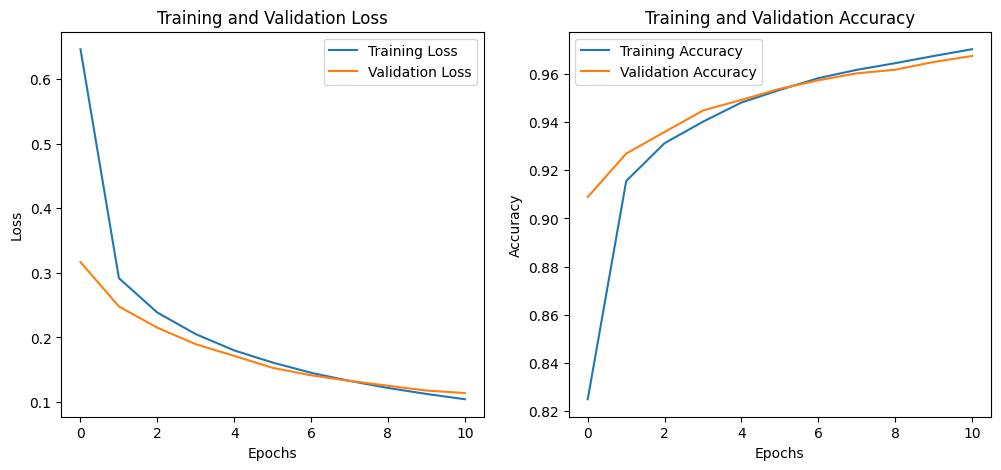

In [11]:
plt.figure(figsize=(12, 5))

plt.subplot(1,2,1)
plt.plot(history.history['loss'], label="Training Loss")
plt.plot(history.history['val_loss'], label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label="Training Accuracy")
plt.plot(history.history['val_accuracy'], label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


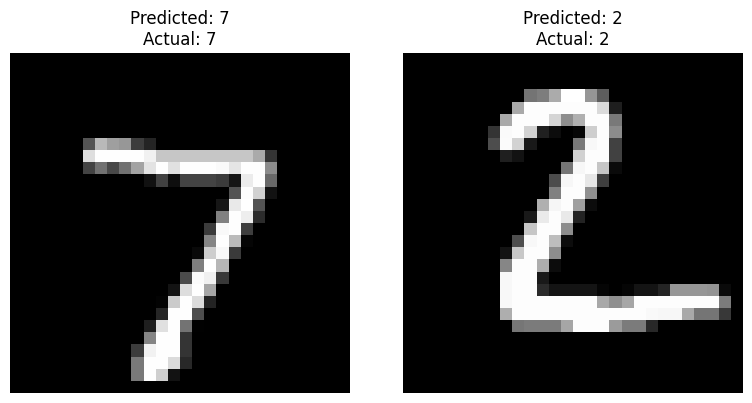

In [12]:
# Display 2 sample images with predicted and actual labels

predictions = model.predict(X_test)

# Get predicted digit (0-9)
predicted_labels = predictions.argmax(axis=1)

plt.figure(figsize=(8, 4))

for i in range(2):
    plt.subplot(1, 2, i + 1)

    # Reshape 784 pixels into 28x28 image
    image = X_test[i].reshape(28, 28)

    plt.imshow(image, cmap='gray')
    plt.title(f"Predicted: {predicted_labels[i]}\nActual: {y_test[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()